# Analysing Pharmaceutical Sales Data
**Tools:** Python 3, Pandas, Matplotlib

**Scenario:** You are a data analyst at a pharmacy chain. Management wants to know which drug categories drive sales, what sells in which period, and whether respiratory drugs (R03) are seasonal, so they can plan stock and purchasing.

**Dataset:** `data/salesdaily.csv` (Kaggle - Pharma Sales Data). Each column M01AB, M01AE, N02BA, N02BE, N05B, N05C, R03, R06 is an ATC drug category; values are quantities sold per day.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
os.makedirs('../outputs', exist_ok=True)

## Step 1 - Load the data

In [2]:
df = pd.read_csv('../data/salesdaily.csv')
df['datum'] = pd.to_datetime(df['datum'])
df = df.sort_values('datum').reset_index(drop=True)
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


## Step 2 - Explore and clean the data
Check size, types, missing values and duplicates before any analysis.

In [3]:
print('Shape:', df.shape)
print('Date range:', df['datum'].min().date(), 'to', df['datum'].max().date())
print('\nMissing values:\n', df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(2)

Shape: (2106, 13)
Date range: 2014-01-02 to 2019-10-08

Missing values:
 datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R03             0
R06             0
Year            0
Month           0
Hour            0
Weekday Name    0
dtype: int64

Duplicate rows: 0


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour
count,2106,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00
mean,2016-11-19 12:00:00,5.03,3.90,3.88,29.92,8.85,0.59,5.51,2.90,2016.40,6.34,275.95
min,2014-01-02 00:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2014.00,1.00,190.00
25%,2015-06-12 06:00:00,3.00,2.34,2.00,19.00,5.00,0.00,1.00,1.00,2015.00,3.00,276.00
50%,2016-11-19 12:00:00,4.99,3.67,3.50,26.90,8.00,0.00,4.00,2.00,2016.00,6.00,276.00
75%,2018-04-29 18:00:00,6.67,5.14,5.20,38.30,12.00,1.00,8.00,4.00,2018.00,9.00,276.00
max,2019-10-08 00:00:00,17.34,14.46,16.00,161.00,54.83,9.00,45.00,15.00,2019.00,12.00,276.00
std,NaN,2.74,2.13,2.38,15.59,5.61,1.09,6.43,2.42,1.67,3.39,1.97


## Step 3 - Define drug columns and helper fields
The eight ATC categories are the sales columns. Year and Month are rebuilt from the date so they are always reliable.

In [4]:
drug_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
drug_cols = [c for c in drug_cols if c in df.columns]
df['Year'] = df['datum'].dt.year
df['Month'] = df['datum'].dt.month
df['MonthName'] = df['datum'].dt.month_name()
print(drug_cols)

['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']


## Q1 - Total sales quantity for each drug category (ATC code)

,Total quantity,Share %
N02BE,63005.4,49.4
N05B,18645.7,14.6
R03,11608.8,9.1
M01AB,10600.9,8.3
M01AE,8204.6,6.4
N02BA,8172.2,6.4
R06,6107.8,4.8
N05C,1250.0,1.0


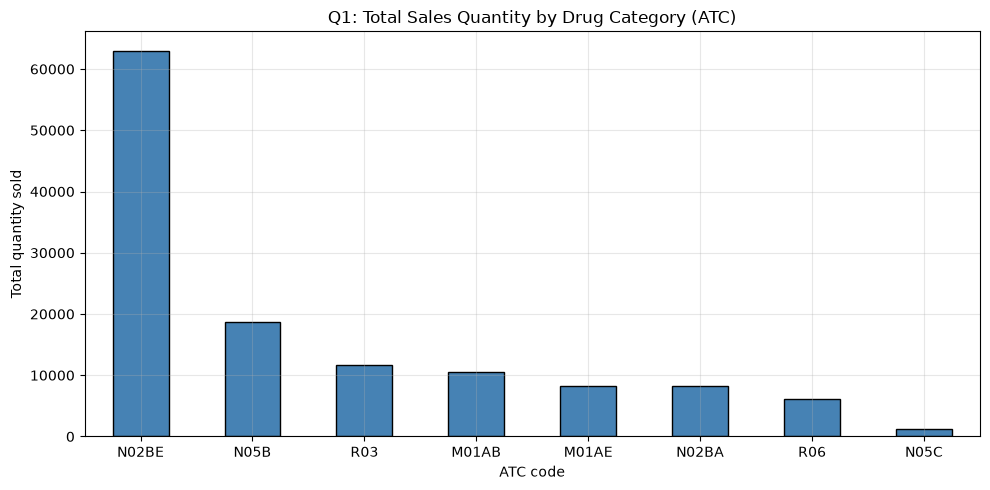

INSIGHT: N02BE is the best-selling category with 63,005 units (49.4% of all sales). N05C sells the least.


In [5]:
q1 = df[drug_cols].sum().sort_values(ascending=False).round(1)
q1_table = q1.rename('Total quantity').to_frame()
q1_table['Share %'] = (q1_table['Total quantity'] / q1_table['Total quantity'].sum() * 100).round(1)
q1_table.to_csv('outputs/q1_total_by_category.csv')
display(q1_table)

ax = q1.plot(kind='bar', color='steelblue', edgecolor='black')
ax.set_title('Q1: Total Sales Quantity by Drug Category (ATC)')
ax.set_xlabel('ATC code'); ax.set_ylabel('Total quantity sold')
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig('outputs/q1_total_by_category.png', dpi=150); plt.show()

print(f"INSIGHT: {q1.index[0]} is the best-selling category with {q1.iloc[0]:,.0f} units "
      f"({q1_table['Share %'].iloc[0]}% of all sales). {q1.index[-1]} sells the least.")

## Q2 - Which individual drug brands have the highest total sales?
The dataset records sales per ATC group (each column is a group of brands), so the 'drug' is the ATC column. We rank them and show the top 5, plus each group's share.

,Total quantity
Drug (ATC),
N02BE,63005.4
N05B,18645.7
R03,11608.8
M01AB,10600.9
M01AE,8204.6


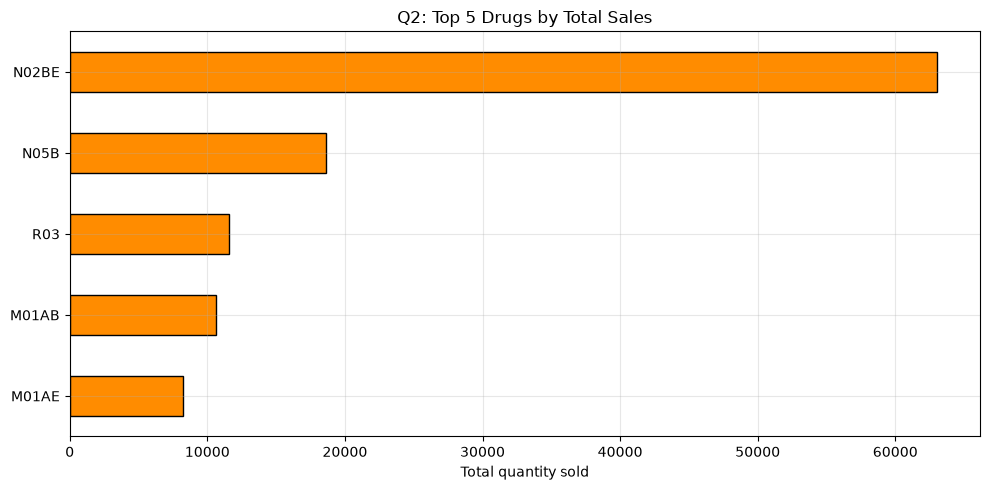

INSIGHT: Top 3 drugs overall are N02BE, N05B, R03 - together 73.1% of all quantity sold.


In [6]:
top_n = 5
q2 = q1.head(top_n)
q2_table = q2.rename('Total quantity').to_frame()
q2_table.index.name = 'Drug (ATC)'
q2_table.to_csv('outputs/q2_top_drugs.csv')
display(q2_table)

ax = q2.sort_values().plot(kind='barh', color='darkorange', edgecolor='black')
ax.set_title(f'Q2: Top {top_n} Drugs by Total Sales')
ax.set_xlabel('Total quantity sold')
plt.tight_layout(); plt.savefig('outputs/q2_top_drugs.png', dpi=150); plt.show()

print('INSIGHT: Top 3 drugs overall are', ', '.join(q2.index[:3]),
      f"- together {q2.iloc[:3].sum()/q1.sum()*100:.1f}% of all quantity sold.")

## Q3 - Top three drugs in January 2015, July 2016 and September 2017

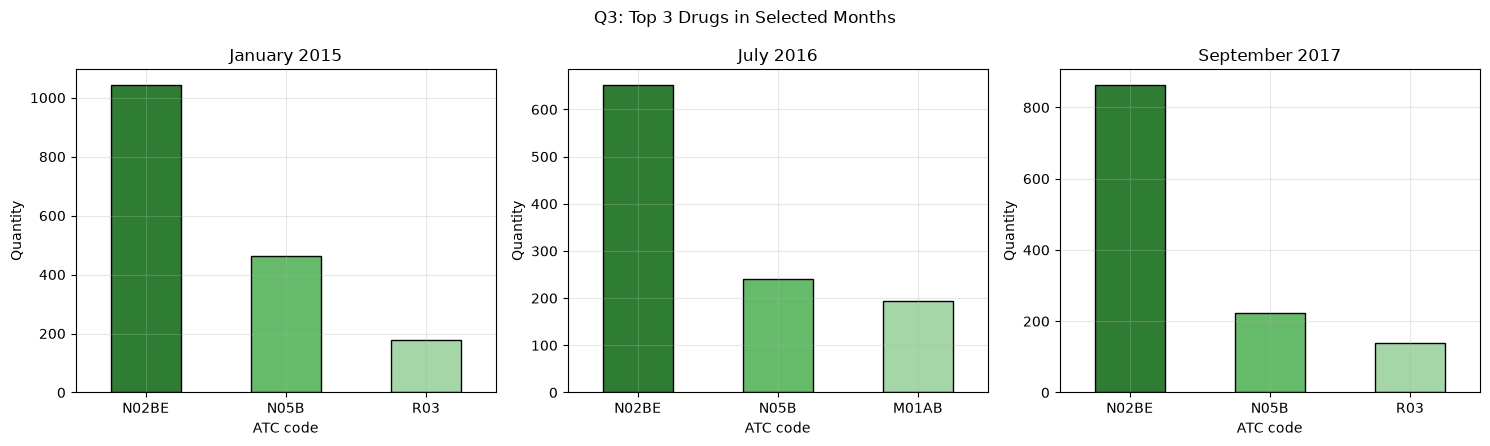

,Period,Rank,Drug,Quantity
0,January 2015,1,N02BE,1044.2
1,January 2015,2,N05B,463.0
2,January 2015,3,R03,177.2
3,July 2016,1,N02BE,652.4
4,July 2016,2,N05B,240.0
5,July 2016,3,M01AB,194.5
6,September 2017,1,N02BE,863.8
7,September 2017,2,N05B,223.0
8,September 2017,3,R03,139.0


INSIGHT: January 2015 - #1 is N02BE (1,044 units).
INSIGHT: July 2016 - #1 is N02BE (652 units).
INSIGHT: September 2017 - #1 is N02BE (864 units).


In [7]:
periods = [(2015, 1, 'January 2015'), (2016, 7, 'July 2016'), (2017, 9, 'September 2017')]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
rows = []
for ax, (yr, mo, label) in zip(axes, periods):
    sub = df[(df['Year'] == yr) & (df['Month'] == mo)]
    top3 = sub[drug_cols].sum().sort_values(ascending=False).head(3).round(1)
    for rank, (drug, qty) in enumerate(top3.items(), 1):
        rows.append({'Period': label, 'Rank': rank, 'Drug': drug, 'Quantity': qty})
    top3.plot(kind='bar', ax=ax, color=['#2e7d32', '#66bb6a', '#a5d6a7'], edgecolor='black')
    ax.set_title(label); ax.set_xlabel('ATC code'); ax.set_ylabel('Quantity')
    ax.tick_params(axis='x', rotation=0)
fig.suptitle('Q3: Top 3 Drugs in Selected Months')
plt.tight_layout(); plt.savefig('outputs/q3_top3_selected_months.png', dpi=150); plt.show()

q3_table = pd.DataFrame(rows)
q3_table.to_csv('outputs/q3_top3_selected_months.csv', index=False)
display(q3_table)

for label, g in q3_table.groupby('Period', sort=False):
    print(f"INSIGHT: {label} - #1 is {g.iloc[0]['Drug']} ({g.iloc[0]['Quantity']:,.0f} units).")

## Q4 - Which drug has sold the most often in 2017?
'Most often' = the number of days in 2017 on which the drug had sales greater than zero. Total quantity is shown as a tie-breaker.

,Days with sales,Total quantity
N02BE,361,9258.8
M01AB,360,1846.6
M01AE,360,1387.3
N05B,356,2555.5
N02BA,350,1288.3
R06,329,988.9
R03,286,1893.6
N05C,99,180.3


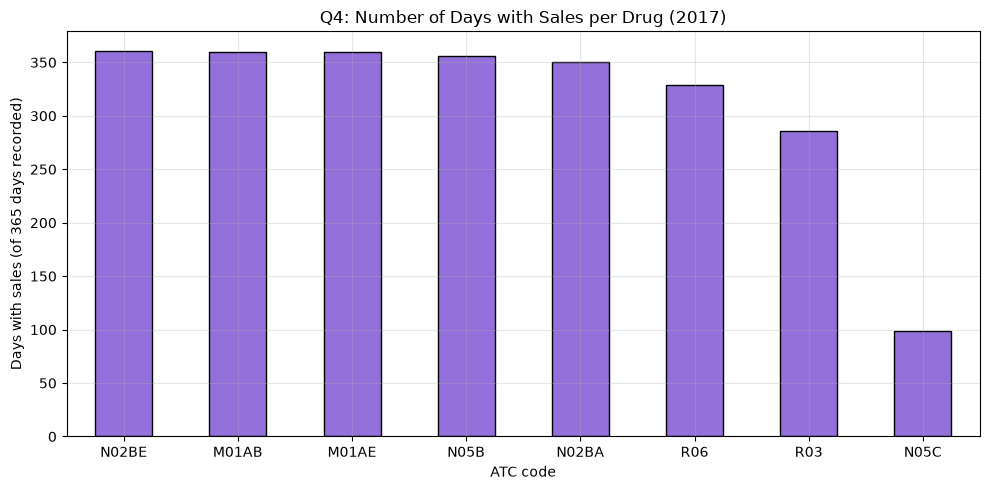

INSIGHT: N02BE sold most often in 2017 (361 days). Total quantity leader: N02BE.


In [8]:
d17 = df[df['Year'] == 2017]
q4_table = pd.DataFrame({
    'Days with sales': (d17[drug_cols] > 0).sum(),
    'Total quantity': d17[drug_cols].sum().round(1)
}).sort_values(['Days with sales', 'Total quantity'], ascending=False)
q4_table.to_csv('outputs/q4_most_frequent_2017.csv')
display(q4_table)

ax = q4_table['Days with sales'].plot(kind='bar', color='mediumpurple', edgecolor='black')
ax.set_title('Q4: Number of Days with Sales per Drug (2017)')
ax.set_xlabel('ATC code'); ax.set_ylabel(f'Days with sales (of {len(d17)} days recorded)')
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig('outputs/q4_most_frequent_2017.png', dpi=150); plt.show()

print(f"INSIGHT: {q4_table.index[0]} sold most often in 2017 "
      f"({q4_table['Days with sales'].iloc[0]} days). Total quantity leader: {q4_table['Total quantity'].idxmax()}.")

## Q5 - Which drug category has the highest average daily sales?

,Average daily sales
N02BE,29.92
N05B,8.85
R03,5.51
M01AB,5.03
M01AE,3.90
N02BA,3.88
R06,2.90
N05C,0.59


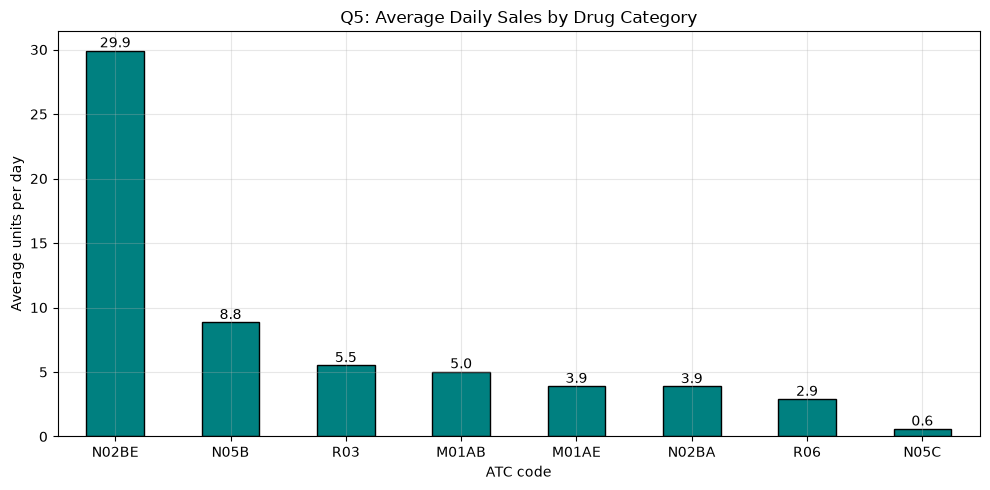

INSIGHT: N02BE has the highest average daily sales (29.9 units/day), about 50.7x the lowest category (N05C).


In [9]:
q5 = df[drug_cols].mean().sort_values(ascending=False).round(2)
q5_table = q5.rename('Average daily sales').to_frame()
q5_table.to_csv('outputs/q5_avg_daily_sales.csv')
display(q5_table)

ax = q5.plot(kind='bar', color='teal', edgecolor='black')
ax.set_title('Q5: Average Daily Sales by Drug Category')
ax.set_xlabel('ATC code'); ax.set_ylabel('Average units per day')
for i, v in enumerate(q5.values):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig('outputs/q5_avg_daily_sales.png', dpi=150); plt.show()

print(f"INSIGHT: {q5.index[0]} has the highest average daily sales ({q5.iloc[0]:.1f} units/day), "
      f"about {q5.iloc[0]/q5.iloc[-1]:.1f}x the lowest category ({q5.index[-1]}).")

## Q6 - Are respiratory drugs (R03) sold more during specific months?
Average daily R03 sales per calendar month across all years (average, not sum, so months with more days are not favoured).

,Avg daily R03 sales
MonthName,
January,6.84
February,6.90
March,6.29
April,5.77
May,5.01
June,4.35
July,2.96
August,3.10
September,4.40


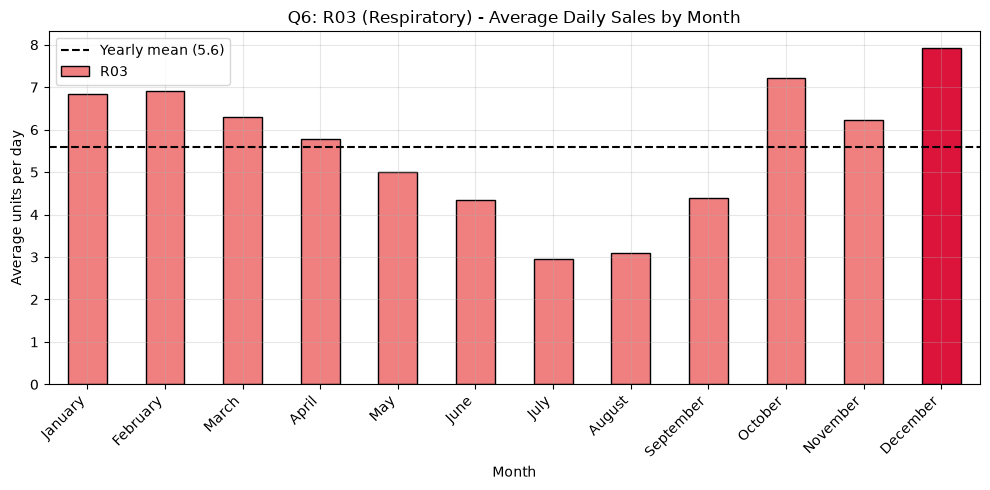

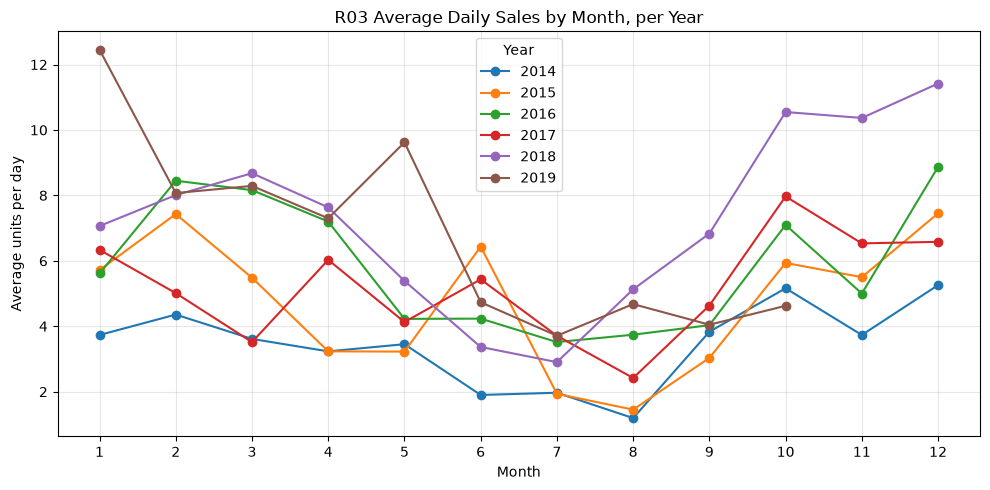

INSIGHT: R03 peaks in December (7.9/day) and is lowest in July (3.0/day). The peak is 168% above the low, so R03 is clearly seasonal.


In [10]:
month_order = ['January','February','March','April','May','June','July','August',
               'September','October','November','December']
r03 = df.groupby('MonthName')['R03'].mean().reindex(month_order).round(2)
r03_table = r03.rename('Avg daily R03 sales').to_frame()
r03_table.to_csv('outputs/q6_r03_by_month.csv')
display(r03_table)

colors = ['crimson' if v == r03.max() else 'lightcoral' for v in r03.values]
ax = r03.plot(kind='bar', color=colors, edgecolor='black')
ax.axhline(r03.mean(), color='black', linestyle='--', label=f'Yearly mean ({r03.mean():.1f})')
ax.set_title('Q6: R03 (Respiratory) - Average Daily Sales by Month')
ax.set_xlabel('Month'); ax.set_ylabel('Average units per day'); ax.legend()
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig('outputs/q6_r03_by_month.png', dpi=150); plt.show()

# Month x Year heatmap-style line chart to check the pattern repeats every year
pivot = df.pivot_table(index='Month', columns='Year', values='R03', aggfunc='mean')
ax = pivot.plot(marker='o')
ax.set_title('R03 Average Daily Sales by Month, per Year')
ax.set_xlabel('Month'); ax.set_ylabel('Average units per day'); ax.set_xticks(range(1, 13))
plt.tight_layout(); plt.savefig('outputs/q6_r03_month_by_year.png', dpi=150); plt.show()

print(f"INSIGHT: R03 peaks in {r03.idxmax()} ({r03.max():.1f}/day) and is lowest in {r03.idxmin()} ({r03.min():.1f}/day). "
      f"The peak is {(r03.max()/r03.min()-1)*100:.0f}% above the low, so R03 is {'clearly seasonal' if r03.max()/r03.min() > 1.2 else 'only mildly seasonal'}.")

## Bonus - Overall trend over time
Monthly total sales of all categories, to see growth or seasonality at a glance.

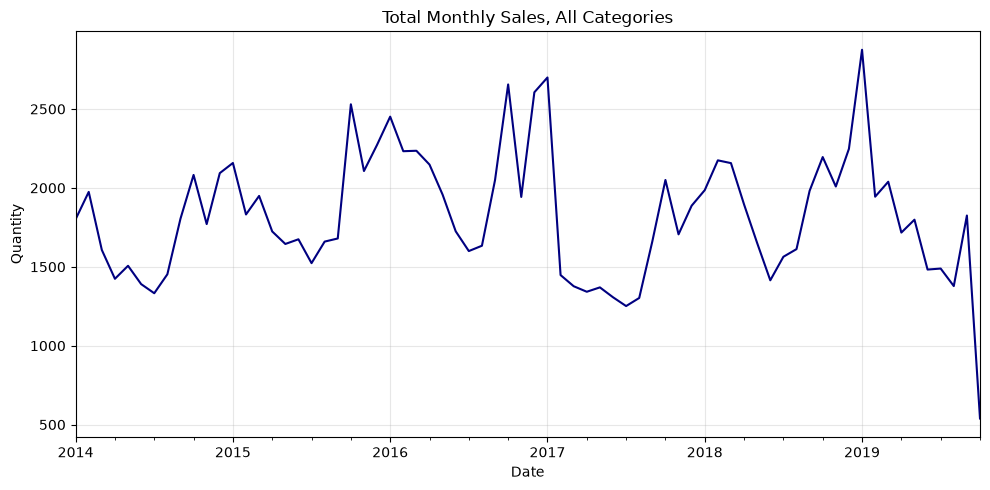

In [11]:
monthly = df.set_index('datum')[drug_cols].resample('MS').sum()
ax = monthly.sum(axis=1).plot(color='navy')
ax.set_title('Total Monthly Sales, All Categories'); ax.set_xlabel('Date'); ax.set_ylabel('Quantity')
plt.tight_layout(); plt.savefig('outputs/bonus_monthly_trend.png', dpi=150); plt.show()

## Summary of findings for management
1. **Q1/Q2:** see the ranking table above - focus purchasing on the top 3 categories.
2. **Q3:** the top sellers can shift between months, so review stock monthly, not yearly.
3. **Q4:** frequency of sale (days sold) shows which drugs are needed every day versus occasionally.
4. **Q5:** average daily sales is the best figure for setting daily stock levels.
5. **Q6:** if R03 shows a clear peak month, increase respiratory stock ahead of it.

All tables are saved as CSV and all charts as PNG in the `outputs/` folder.